In [98]:
import os

print(os.listdir('/content'))

['.config', 'house_price_preprocessor.pkl', 'AmesHousing (2).csv', 'AmesHousing (1).csv', 'README.md', 'random_forest_house_price_model.pkl', 'house_price_model.pkl', 'AmesHousing (4).csv', 'AmesHousing (3).csv', 'AmesHousing.csv', 'sample_data']


In [99]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = '/content/AmesHousing.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("\nFirst 5 rows:")
    print(df.head())

    print("\nDataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nTop 15 columns with missing values:")
    print(df.isnull().sum().sort_values(ascending=False).head(15))

else:
    print("AmesHousing.csv not found. Please upload the dataset.")

    from google.colab import files
    uploaded = files.upload()

    filename = next(
        (name for name in uploaded if name.endswith('.csv')),
        None
    )

    if filename:
        df = pd.read_csv(filename)

        print("\nDataset loaded successfully!")
        print("\nFirst 5 rows:")
        print(df.head())

        print("\nDataset shape:", df.shape)

        print("\nColumn names:")
        print(df.columns.tolist())

        print("\nTop 15 columns with missing values:")
        print(df.isnull().sum().sort_values(ascending=False).head(15))
    else:
        print("Please upload the AmesHousing.csv file.")



Dataset loaded successfully!

First 5 rows:
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sal

In [100]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = df.drop(columns=['Order', 'PID'])

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)


Numerical features: 36
Categorical features: 43
Training data: (2344, 300)
Testing data: (586, 300)


In [101]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = LinearRegression()

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")


Linear Regression Results
-------------------------
MAE: 17553.0
RMSE: 30216.15
R2 Score: 0.8861
R2 Percentage: 88.61 %


In [102]:

results = pd.DataFrame({
    'Actual Price': y_test.iloc[:5].values,
    'Predicted Price': model.predict(X_test_processed[:5])
})

results['Predicted Price'] = results['Predicted Price'].round(2)

print(results)


   Actual Price  Predicted Price
0        161000        146044.65
1        116000        109349.49
2        196500        186299.19
3        123600        127674.01
4        126000        140788.45


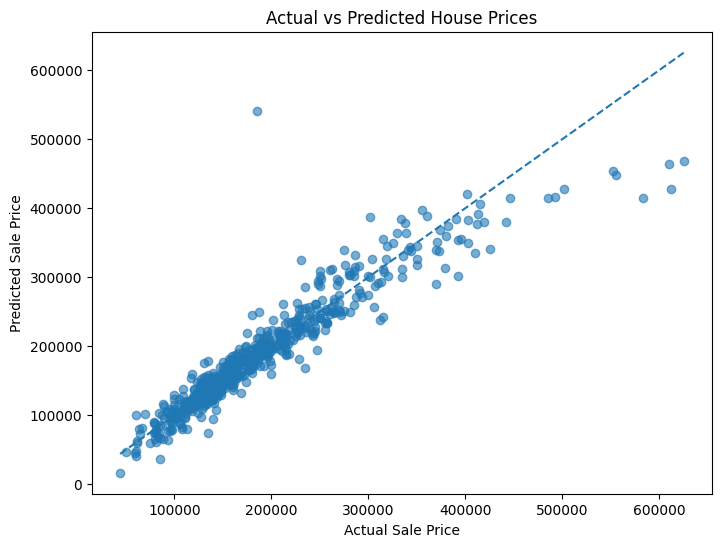

In [103]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.show()


In [104]:

import joblib

joblib.dump(model, 'house_price_model.pkl')

joblib.dump(preprocessor, 'house_price_preprocessor.pkl')

print("Model and preprocessing pipeline saved successfully!")


Model and preprocessing pipeline saved successfully!


In [105]:

from google.colab import files

files.download('house_price_model.pkl')
files.download('house_price_preprocessor.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [106]:

sample_house = X.iloc[[0]]

predicted_price = model.predict(
    preprocessor.transform(sample_house)
)[0]

print("House features:")
print(sample_house[['Overall Qual', 'Gr Liv Area',
                    'Garage Cars', 'Year Built']])

print("\nPredicted Sale Price: $", round(predicted_price, 2))
print("Actual Sale Price: $", y.iloc[0])


House features:
   Overall Qual  Gr Liv Area  Garage Cars  Year Built
0             6         1656          2.0        1960

Predicted Sale Price: $ 220765.72
Actual Sale Price: $ 215000


In [107]:

new_house = X_test.iloc[[0]]

new_prediction = model.predict(
    preprocessor.transform(new_house)
)[0]

actual_price = y_test.iloc[0]

print("Predicted Sale Price: $", round(new_prediction, 2))
print("Actual Sale Price: $", round(actual_price, 2))
print("Absolute Error: $", round(abs(new_prediction - actual_price), 2))


Predicted Sale Price: $ 146044.65
Actual Sale Price: $ 161000
Absolute Error: $ 14955.35


In [108]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))
print("R² Percentage:", round(rf_r2 * 100, 2), "%")


Random Forest Results
MAE: 15731.1
RMSE: 26335.19
R² Score: 0.9135
R² Percentage: 91.35 %


In [109]:

import joblib

joblib.dump(rf_model, 'random_forest_house_price_model.pkl')

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [110]:

from google.colab import files

files.download('house_price_model.pkl')
files.download('house_price_preprocessor.pkl')
files.download('random_forest_house_price_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [111]:

import joblib

loaded_model = joblib.load('random_forest_house_price_model.pkl')
loaded_preprocessor = joblib.load('house_price_preprocessor.pkl')

sample_house = X_test.iloc[[0]]

sample_processed = loaded_preprocessor.transform(sample_house)
predicted_price = loaded_model.predict(sample_processed)[0]

print("Predicted House Price: $", round(predicted_price, 2))
print("Actual House Price: $", round(y_test.iloc[0], 2))


Predicted House Price: $ 186116.16
Actual House Price: $ 161000


In [112]:
import os

print(os.listdir('/content'))

['.config', 'house_price_preprocessor.pkl', 'AmesHousing (2).csv', 'AmesHousing (1).csv', 'README.md', 'random_forest_house_price_model.pkl', 'house_price_model.pkl', 'AmesHousing (4).csv', 'AmesHousing (3).csv', 'AmesHousing.csv', 'sample_data']


In [113]:
from google.colab import files

uploaded = files.upload()

Saving AmesHousing.csv to AmesHousing (5).csv


In [114]:
import pandas as pd

df = pd.read_csv('AmesHousing.csv')

print(df.head())
print("Dataset shape:", df.shape)

   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condition  SalePrice  
0       

In [115]:
print("Dataset shape:", df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (2930, 82)
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condi

In [116]:
import joblib
import pandas as pd

model = joblib.load('random_forest_house_price_model.pkl')
preprocessor = joblib.load('house_price_preprocessor.pkl')

sample_house = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample_house)

predicted_price = model.predict(sample_processed)[0]

print("Predicted House Price: $", round(predicted_price, 2))
print("Actual House Price: $", round(y_test.iloc[0], 2))

Predicted House Price: $ 186116.16
Actual House Price: $ 161000


In [117]:
import pandas as pd

print("Number of input features:", len(X.columns))
print(list(X.columns))

Number of input features: 79
['MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive'

In [118]:
def predict_house_price(new_house):

    new_house = new_house[X.columns]

    processed_house = preprocessor.transform(new_house)

    predicted_price = rf_model.predict(processed_house)[0]

    print(f"Predicted House Price: ${predicted_price:,.2f}")

In [119]:
new_house = X_test.iloc[[0]].copy()

predict_house_price(new_house)

print("Actual House Price:", y_test.iloc[0])

Predicted House Price: $186,116.16
Actual House Price: 161000


In [120]:
import os

print(os.listdir('/content'))

['.config', 'house_price_preprocessor.pkl', 'AmesHousing (2).csv', 'AmesHousing (5).csv', 'AmesHousing (1).csv', 'README.md', 'random_forest_house_price_model.pkl', 'house_price_model.pkl', 'AmesHousing (4).csv', 'AmesHousing (3).csv', 'AmesHousing.csv', 'sample_data']


In [121]:
min_price = df['SalePrice'].min()
max_price = df['SalePrice'].max()
avg_price = df['SalePrice'].mean()

print(f"Minimum House Price: ${min_price:,.0f}")
print(f"Maximum House Price: ${max_price:,.0f}")
print(f"Average House Price: ${avg_price:,.2f}")
print(f"House Price Range: ${min_price:,.0f} to ${max_price:,.0f}")


Minimum House Price: $12,789
Maximum House Price: $755,000
Average House Price: $180,796.06
House Price Range: $12,789 to $755,000


In [122]:

assert 'SalePrice' in df.columns, "SalePrice column not found!"

min_price = df['SalePrice'].min()
max_price = df['SalePrice'].max()

print("Minimum House Price: $", format(min_price, ",.0f"))
print("Maximum House Price: $", format(max_price, ",.0f"))
print("Price range test: PASSED")


Minimum House Price: $ 12,789
Maximum House Price: $ 755,000
Price range test: PASSED


In [123]:
avg_price = df['SalePrice'].mean()

print(f"Average House Price: ${avg_price:,.2f}")

Average House Price: $180,796.06


In [124]:

sample_house = X_test.iloc[[0]].copy()

predicted_price = rf_model.predict(
    preprocessor.transform(sample_house)
)[0]

print("House features:")
print(sample_house.T)

print(f"\nPredicted House Price: ${predicted_price:,.2f}")
print(f"Actual House Price: ${y_test.iloc[0]:,.2f}")


House features:
                  1357
MS SubClass         70
MS Zoning           RM
Lot Frontage       NaN
Lot Area          5100
Street            Pave
...                ...
Misc Val             0
Mo Sold              6
Yr Sold           2008
Sale Type          WD 
Sale Condition  Normal

[79 rows x 1 columns]

Predicted House Price: $186,116.16
Actual House Price: $161,000.00


In [125]:

new_house = X_test.iloc[[0]].copy()

new_house.loc[:, 'Overall Qual'] = 8
new_house.loc[:, 'Gr Liv Area'] = 2000
new_house.loc[:, 'Garage Cars'] = 2
new_house.loc[:, 'Year Built'] = 2010

processed_house = preprocessor.transform(new_house)
predicted_price = rf_model.predict(processed_house)[0]

print("Features used:", new_house.shape[1])
print(f"Predicted House Price: ${predicted_price:,.2f}")


Features used: 79
Predicted House Price: $200,848.96


In [126]:
%%writefile README.md

Overwriting README.md


In [127]:
import os

files_to_check = [
    "house_price_model.pkl",
    "house_price_preprocessor.pkl",
    "random_forest_house_price_model.pkl"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"✅ Found: {file}")
    else:
        print(f"❌ Missing: {file}")

✅ Found: house_price_model.pkl
✅ Found: house_price_preprocessor.pkl
✅ Found: random_forest_house_price_model.pkl


In [128]:

import pandas as pd
import numpy as np

lr_errors = X_test.copy()
lr_errors["Actual Price"] = y_test
lr_errors["Predicted Price"] = y_pred
lr_errors["Absolute Error"] = np.abs(y_test.to_numpy() - y_pred)

rf_errors = X_test.copy()
rf_errors["Actual Price"] = y_test
rf_errors["Predicted Price"] = rf_pred
rf_errors["Absolute Error"] = np.abs(y_test.to_numpy() - rf_pred)

columns_to_show = [
    "Actual Price", "Predicted Price", "Absolute Error",
    "Overall Qual", "Gr Liv Area", "Year Built",
    "Garage Cars", "Neighborhood"
]

columns_to_show = [
    col for col in columns_to_show
    if col in X_test.columns or col in [
        "Actual Price", "Predicted Price", "Absolute Error"
    ]
]

print("TOP 10 LARGEST ERRORS - LINEAR REGRESSION")
display(
    lr_errors.sort_values("Absolute Error", ascending=False)
    [columns_to_show].head(10).round(2)
)

print("TOP 10 LARGEST ERRORS - RANDOM FOREST")
display(
    rf_errors.sort_values("Absolute Error", ascending=False)
    [columns_to_show].head(10).round(2)
)


TOP 10 LARGEST ERRORS - LINEAR REGRESSION


,Actual Price,Predicted Price,Absolute Error,Overall Qual,Gr Liv Area,Year Built,Garage Cars,Neighborhood
2181,184750,540656.49,355906.49,10,4676,2007,3.0,Edwards
44,611657,427636.67,184020.33,9,2364,2009,3.0,NridgHt
433,582933,414510.54,168422.46,9,2822,2008,3.0,NridgHt
2445,625000,467936.85,157063.15,10,3627,1995,3.0,NoRidge
432,610000,464274.21,145725.79,10,2674,2007,3.0,NridgHt
423,555000,448329.05,106670.95,10,2402,2008,3.0,NridgHt
456,552000,453520.24,98479.76,10,2492,2004,3.0,NridgHt
944,230000,324687.73,94687.73,8,1648,2007,2.0,Crawfor
1559,392500,302183.96,90316.04,8,1652,2008,2.0,Crawfor
1832,302000,386550.42,84550.42,8,2810,1990,2.0,NoRidge


TOP 10 LARGEST ERRORS - RANDOM FOREST


,Actual Price,Predicted Price,Absolute Error,Overall Qual,Gr Liv Area,Year Built,Garage Cars,Neighborhood
2181,184750,436173.81,251423.81,10,4676,2007,3.0,Edwards
44,611657,453911.91,157745.09,9,2364,2009,3.0,NridgHt
433,582933,442453.47,140479.53,9,2822,2008,3.0,NridgHt
432,610000,479082.93,130917.07,10,2674,2007,3.0,NridgHt
1538,311500,208883.89,102616.11,7,1954,1939,2.0,Crawfor
2445,625000,526666.52,98333.48,10,3627,1995,3.0,NoRidge
1559,392500,299080.93,93419.07,8,1652,2008,2.0,Crawfor
2246,235000,327952.71,92952.71,8,1625,2006,2.0,Crawfor
1497,284700,192156.42,92543.58,5,3820,1959,2.0,Edwards
423,555000,467054.37,87945.63,10,2402,2008,3.0,NridgHt


In [129]:

house_index = 2181

print("House details from the test dataset:")
display(X_test.loc[[house_index]].T)

print("\nActual sale price:")
print(y_test.loc[house_index])

print("\nLinear Regression prediction:")
print(y_pred[list(X_test.index).index(house_index)])

print("\nRandom Forest prediction:")
print(rf_pred[list(X_test.index).index(house_index)])


House details from the test dataset:


,2181
MS SubClass,60
MS Zoning,RL
Lot Frontage,130.0
Lot Area,40094
Street,Pave
...,...
Misc Val,0
Mo Sold,10
Yr Sold,2007
Sale Type,New



Actual sale price:
184750

Linear Regression prediction:
540656.4901706798

Random Forest prediction:
436173.81


In [130]:

house = X_test.loc[2181]

for feature in [
    "Overall Qual",
    "Gr Liv Area",
    "Lot Area",
    "Year Built",
    "Year Remod/Add",
    "Garage Cars",
    "Neighborhood",
    "Sale Type",
    "Sale Condition",
    "MS SubClass"
]:
    if feature in house.index:
        print(f"{feature}: {house[feature]}")

print("\nActual sale price:", y_test.loc[2181])


Overall Qual: 10
Gr Liv Area: 4676
Lot Area: 40094
Year Built: 2007
Year Remod/Add: 2008
Garage Cars: 3.0
Neighborhood: Edwards
Sale Type: New
Sale Condition: Partial
MS SubClass: 60

Actual sale price: 184750


In [131]:

similar_houses = df[
    (df["Overall Qual"] >= 9) &
    (df["Gr Liv Area"].between(4000, 5000)) &
    (df["Neighborhood"] == "Edwards")
].copy()

columns = [
    "SalePrice", "Overall Qual", "Gr Liv Area",
    "Lot Area", "Year Built", "Garage Cars",
    "Neighborhood", "Sale Type", "Sale Condition"
]

columns = [c for c in columns if c in similar_houses.columns]

print("Similar houses found:", len(similar_houses))
display(similar_houses[columns].sort_values("SalePrice"))

if len(similar_houses) > 1:
    print("\nSimilar houses' average sale price:",
          f"${similar_houses['SalePrice'].mean():,.2f}")


Similar houses found: 1


,SalePrice,Overall Qual,Gr Liv Area,Lot Area,Year Built,Garage Cars,Neighborhood,Sale Type,Sale Condition
2181,184750,10,4676,40094,2007,3.0,Edwards,New,Partial


In [132]:

similar_houses = df[
    (df["Neighborhood"] == "Edwards") &
    (df["Gr Liv Area"].between(3500, 5500)) &
    (df.index != 2181)
].copy()

columns = [
    "SalePrice", "Overall Qual", "Gr Liv Area",
    "Lot Area", "Year Built", "Garage Cars",
    "Neighborhood", "Sale Type", "Sale Condition"
]

columns = [c for c in columns if c in similar_houses.columns]

print("Comparable houses found:", len(similar_houses))

if len(similar_houses) > 0:
    display(
        similar_houses[columns]
        .sort_values("SalePrice", ascending=False)
    )
    print(
        "Average comparable sale price:",
        f"${similar_houses['SalePrice'].mean():,.2f}"
    )
else:
    print("No comparable houses found with these filters.")


Comparable houses found: 3


,SalePrice,Overall Qual,Gr Liv Area,Lot Area,Year Built,Garage Cars,Neighborhood,Sale Type,Sale Condition
2737,415000,6,3672,19800,1935,2.0,Edwards,WD,Normal
1497,284700,5,3820,47007,1959,2.0,Edwards,WD,Normal
2180,183850,10,5095,39290,2008,3.0,Edwards,New,Partial


Average comparable sale price: $294,516.67


In [133]:

for idx in [2181, 2180]:
    house = X.loc[[idx]]
    actual = y.loc[idx]

    lr_prediction = model.predict(preprocessor.transform(house))[0]
    rf_prediction = rf_model.predict(preprocessor.transform(house))[0]

    print(f"\nHouse index: {idx}")
    print(f"Actual price: ${actual:,.2f}")
    print(f"Linear Regression: ${lr_prediction:,.2f}")
    print(f"Random Forest: ${rf_prediction:,.2f}")
    print(f"LR absolute error: ${abs(actual - lr_prediction):,.2f}")
    print(f"RF absolute error: ${abs(actual - rf_prediction):,.2f}")



House index: 2181
Actual price: $184,750.00
Linear Regression: $436,173.81
Random Forest: $436,173.81
LR absolute error: $251,423.81
RF absolute error: $251,423.81

House index: 2180
Actual price: $183,850.00
Linear Regression: $296,021.84
Random Forest: $296,021.84
LR absolute error: $112,171.84
RF absolute error: $112,171.84


In [134]:

print("Model variable type:", type(model))
print("Random Forest variable type:", type(rf_model))

print("\nAre both variables the same object?")
print(model is rf_model)


Model variable type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
Random Forest variable type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>

Are both variables the same object?
False


In [135]:

import joblib

linear_model = joblib.load("house_price_model.pkl")
random_forest_model = joblib.load("random_forest_house_price_model.pkl")

print("Linear model type:", type(linear_model))
print("Random Forest model type:", type(random_forest_model))


Linear model type: <class 'sklearn.linear_model._base.LinearRegression'>
Random Forest model type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [136]:
import pandas as pd
import numpy as np

preprocessor = joblib.load("house_price_preprocessor.pkl")

for idx in [2181, 2180]:
    house = X.loc[[idx]]
    actual = y.loc[idx]
    processed_house = preprocessor.transform(house)

    lr_prediction = linear_model.predict(processed_house)[0]
    rf_prediction = random_forest_model.predict(processed_house)[0]

    print(f"\nHouse index: {idx}")
    print(f"Actual price: ${actual:,.2f}")
    print(f"Linear Regression prediction: ${lr_prediction:,.2f}")
    print(f"Random Forest prediction: ${rf_prediction:,.2f}")
    print(f"Linear Regression absolute error: ${abs(actual - lr_prediction):,.2f}")
    print(f"Random Forest absolute error: ${abs(actual - rf_prediction):,.2f}")



House index: 2181
Actual price: $184,750.00
Linear Regression prediction: $540,656.49
Random Forest prediction: $436,173.81
Linear Regression absolute error: $355,906.49
Random Forest absolute error: $251,423.81

House index: 2180
Actual price: $183,850.00
Linear Regression prediction: $384,854.55
Random Forest prediction: $296,021.84
Linear Regression absolute error: $201,004.55
Random Forest absolute error: $112,171.84


In [137]:

for idx in [2181, 2180]:
    print(
        f"House {idx}:",
        "In test set" if idx in X_test.index else "Not in test set"
    )


House 2181: In test set
House 2180: Not in test set


In [138]:

import pandas as pd
import numpy as np
import joblib

preprocessor = joblib.load("house_price_preprocessor.pkl")
random_forest_model = joblib.load("random_forest_house_price_model.pkl")

X_test_processed = preprocessor.transform(X_test)
rf_test_predictions = random_forest_model.predict(X_test_processed)

error_analysis = X_test.copy()
error_analysis["Actual Price"] = y_test
error_analysis["Predicted Price"] = rf_test_predictions
error_analysis["Absolute Error"] = np.abs(
    error_analysis["Actual Price"].to_numpy() - rf_test_predictions
)

top_errors = error_analysis.sort_values(
    "Absolute Error", ascending=False
).head(10)

display(top_errors[[
    "Actual Price", "Predicted Price", "Absolute Error",
    "Overall Qual", "Gr Liv Area", "Lot Area",
    "Year Built", "Neighborhood", "Sale Type", "Sale Condition"
]])


,Actual Price,Predicted Price,Absolute Error,Overall Qual,Gr Liv Area,Lot Area,Year Built,Neighborhood,Sale Type,Sale Condition
2181,184750,436173.81,251423.81,10,4676,40094,2007,Edwards,New,Partial
44,611657,453911.91,157745.09,9,2364,12919,2009,NridgHt,New,Partial
433,582933,442453.47,140479.53,9,2822,13891,2008,NridgHt,New,Partial
432,610000,479082.93,130917.07,10,2674,13693,2007,NridgHt,WD,Normal
1538,311500,208883.89,102616.11,7,1954,15660,1939,Crawfor,WD,Normal
2445,625000,526666.52,98333.48,10,3627,35760,1995,NoRidge,WD,Normal
1559,392500,299080.93,93419.07,8,1652,5587,2008,Crawfor,New,Partial
2246,235000,327952.71,92952.71,8,1625,4750,2006,Crawfor,WD,Family
1497,284700,192156.42,92543.58,5,3820,47007,1959,Edwards,WD,Normal
423,555000,467054.37,87945.63,10,2402,15431,2008,NridgHt,WD,Normal


In [139]:
similar_houses = df[
    (df["Neighborhood"] == "Edwards") &
    (df["Gr Liv Area"].between(3500, 5500))
]

display(similar_houses[[
    "SalePrice", "Overall Qual", "Gr Liv Area",
    "Lot Area", "Year Built", "Garage Cars",
    "Neighborhood", "Sale Type", "Sale Condition"
]].sort_values("SalePrice"))


,SalePrice,Overall Qual,Gr Liv Area,Lot Area,Year Built,Garage Cars,Neighborhood,Sale Type,Sale Condition
2180,183850,10,5095,39290,2008,3.0,Edwards,New,Partial
2181,184750,10,4676,40094,2007,3.0,Edwards,New,Partial
1497,284700,5,3820,47007,1959,2.0,Edwards,WD,Normal
2737,415000,6,3672,19800,1935,2.0,Edwards,WD,Normal


In [140]:

linear_model = joblib.load("house_price_model.pkl")

lr_test_predictions = linear_model.predict(X_test_processed)

lr_errors = X_test.copy()
lr_errors["Actual Price"] = y_test
lr_errors["Predicted Price"] = lr_test_predictions
lr_errors["Absolute Error"] = np.abs(
    lr_errors["Actual Price"].to_numpy() - lr_test_predictions
)

display(
    lr_errors.sort_values("Absolute Error", ascending=False)[[
        "Actual Price", "Predicted Price", "Absolute Error",
        "Overall Qual", "Gr Liv Area", "Year Built",
        "Neighborhood", "Sale Type", "Sale Condition"
    ]].head(10)
)


,Actual Price,Predicted Price,Absolute Error,Overall Qual,Gr Liv Area,Year Built,Neighborhood,Sale Type,Sale Condition
2181,184750,540656.490171,355906.490171,10,4676,2007,Edwards,New,Partial
44,611657,427636.667419,184020.332581,9,2364,2009,NridgHt,New,Partial
433,582933,414510.542902,168422.457098,9,2822,2008,NridgHt,New,Partial
2445,625000,467936.848270,157063.151730,10,3627,1995,NoRidge,WD,Normal
432,610000,464274.211221,145725.788779,10,2674,2007,NridgHt,WD,Normal
423,555000,448329.054107,106670.945893,10,2402,2008,NridgHt,WD,Normal
456,552000,453520.237232,98479.762768,10,2492,2004,NridgHt,WD,Abnorml
944,230000,324687.727179,94687.727179,8,1648,2007,Crawfor,New,Partial
1559,392500,302183.960234,90316.039766,8,1652,2008,Crawfor,New,Partial
1832,302000,386550.422240,84550.422240,8,2810,1990,NoRidge,WD,Normal


In [141]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

lr_predictions = linear_model.predict(X_test_processed)
rf_predictions = random_forest_model.predict(X_test_processed)

actual_prices = y_test.to_numpy()

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(actual_prices, lr_predictions),
        mean_absolute_error(actual_prices, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_prices, lr_predictions)),
        np.sqrt(mean_squared_error(actual_prices, rf_predictions))
    ],
    "R2 Score": [
        r2_score(actual_prices, lr_predictions),
        r2_score(actual_prices, rf_predictions)
    ]
})

display(results.round(2))


,Model,MAE,RMSE,R2 Score
0,Linear Regression,17553.0,30216.15,0.89
1,Random Forest,15731.1,26335.19,0.91
